# BT4012 Kaggle Competition AY2627 Semester 1

Version 23B: Unsupervised GAT Node Embeddings + XGBoost & LightGBM Pipeline. This notebook outputs `submission_version_23B.csv`.

By: E1156227

# 1. Imports and Set Up

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import rankdata
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)

import networkx as nx
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek

import warnings, copy, time
warnings.filterwarnings("ignore")

In [ ]:
# Model Specific Imports
import xgboost as xgb
import lightgbm as lgb

# Optuna for hyperparameter search
import optuna
from optuna.samplers import TPESampler

# GAT Imports
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GATv2Conv
from torch_geometric.data import Data
from torch_geometric.utils import negative_sampling

In [ ]:
# Configurations
# Input file locations
TRAIN_PATH = "train.csv"
TEST_PATH = "test.csv"
EDGELIST_PATH = "txs_edgelist.csv"

# Column names used throughout the notebook
ID_COL = "txId"
TIME_COL = "time_step"
TARGET_COL = "label"

# Global random seed (used for reproducibility)
SEED = 42

# Configurations for XGBoost and LightGBM
N_JOBS = 8
TOP_K = 20
N_OPTUNA_TRIALS = 40

# Configurations for GAT
N_OPTUNA_TRIALS_GAT = 10
MAX_EPOCHS = 100
PATIENCE = 10
N_SEEDS = 3

# Version tag used in the submission file name
VER_NO = "23B"

# Seed the global random number generators and reduce Optuna log noise
np.random.seed(SEED)
torch.manual_seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [ ]:
# Use GPU when available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


# 2. Load the Dataset

In [ ]:
# Load the labelled training transactions (txId, time_step, 165 features, label)
df = pd.read_csv(TRAIN_PATH)

print("train dataframe shape: ", df.shape)
print("view the training dataframe:")
df.head(10)

train dataframe shape:  (141772, 168)
view the training dataframe:


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN
5,230459870,1,0.961040,-0.081127,-1.201369,1.303743,0.333276,1.480381,-0.061584,-0.163577,...,-0.422589,-0.226790,-0.117629,0.018279,0.277775,0.413931,1.149556,-0.696053,-0.695540,NaN
6,230333930,1,-0.171264,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.161887,...,-0.607306,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
7,230595899,1,-0.171755,-0.184668,-1.201369,-0.046932,-0.043875,-0.029140,-0.061584,-0.163552,...,0.704641,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
8,232013274,1,-0.123127,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.112635,...,-0.235168,-0.979074,-0.978556,-0.098889,-0.087490,-0.084674,-0.140597,1.519700,1.521399,NaN
9,232029206,1,-0.005027,0.578941,-0.091383,4.380281,-0.063725,4.667146,0.851305,-0.163645,...,-0.613614,0.241128,0.241406,0.604120,0.008632,-0.131155,0.333211,-0.120613,-0.119792,0.0


In [ ]:
# Load the test transactions (later time steps, no labels, contains the submission 'index')
test = pd.read_csv(TEST_PATH)

print("test dataframe shape: ", test.shape)
print("view the testing dataframe:")
test.head(10)

test dataframe shape:  (15329, 168)
view the testing dataframe:


,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165
0,0,200459281,36,-0.172879,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,...,2.262621,1.947206,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
1,1,199944769,36,-0.172828,0.339970,1.018602,0.178180,-0.043875,0.222447,-0.061584,...,-0.524789,-0.531617,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,2,198827545,36,-0.172282,0.837998,1.018602,0.553368,-0.043875,0.641758,-0.061584,...,1.149152,1.070472,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
3,3,200997190,36,-0.172926,0.156148,1.573595,-0.046932,-0.043875,-0.029140,-0.061584,...,0.125358,0.080204,1.461330,1.461369,0.018279,-0.049041,-0.038193,-0.011377,-1.760926,-1.760984
4,4,200996856,36,-0.171396,1.311640,1.573595,0.478330,-0.004174,0.474034,-0.061584,...,-0.106650,-0.137402,0.258822,0.729391,0.018279,0.393121,0.680158,0.462432,0.359796,1.091185
5,5,200620377,36,-0.172426,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,...,-0.293127,-0.373931,1.461330,1.461369,0.018279,0.335448,0.891428,0.850093,1.519700,1.521399
6,6,200618680,36,-0.172481,-0.093552,-0.091383,-0.121970,-0.043875,-0.113002,-0.061584,...,-0.562153,-0.588384,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
7,7,199991289,36,-0.168641,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,...,0.185141,0.029745,-0.979074,-0.978556,-0.098889,-0.087490,-0.084674,-0.140597,1.519700,1.521399
8,8,4209720,36,0.206548,2.284715,1.573595,0.478330,0.889077,0.474034,-0.061584,...,-0.122282,-0.428070,0.060625,0.154399,-0.098889,0.412346,0.119474,-0.065218,0.322678,0.375230
9,9,200032559,36,0.249975,5.340681,2.128587,4.680431,-0.043875,4.247834,-0.061584,...,-0.248290,-0.323472,-0.979074,-0.978556,0.018279,4.584053,11.163745,10.369333,1.519700,1.521399


In [ ]:
# Load the transaction graph: one row per payment-flow edge (txId1 -> txId2)
edgelist_df = pd.read_csv(EDGELIST_PATH)

print("edgelist dataframe shape: ", edgelist_df.shape)
print("view the edgelist dataframe:")
edgelist_df.head(10)

edgelist dataframe shape:  (234355, 2)
view the edgelist dataframe:


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206
5,232344069,27553029
6,36411953,230405052
7,34194980,5529846
8,3881097,232457116
9,230409257,32877982


# 3. Data Exploration & Preparation

In [ ]:
# Summary statistics of every training column
# Description
print("Exploring Train Dataset")
print("df describe:", df.describe(include="all"))

Exploring Train Dataset
df describe:                txId      time_step         feat_1         feat_2         feat_3         feat_4         feat_5         feat_6  \
count  1.417720e+05  141772.000000  141772.000000  141772.000000  141772.000000  141772.000000  141772.000000  141772.000000   
mean   2.004880e+08      15.781903       0.018390      -0.108169      -0.300165      -0.002866       0.000438      -0.005162   
std    1.130078e+08      10.533858       1.119660       0.395017       0.961251       0.990140       1.113030       0.994618   
min    2.534000e+03       1.000000      -0.172983      -0.210553      -1.756361      -0.121970      -0.063725      -0.113002   
25%    9.433347e+07       6.000000      -0.172436      -0.184668      -1.201369      -0.121970      -0.043875      -0.113002   
50%    2.241956e+08      14.000000      -0.168768      -0.158783      -0.646376      -0.121970      -0.043875      -0.113002   
75%    2.943870e+08      24.000000      -0.135555      -0.107012   

In [ ]:
# Column types
print("df info:")
df.info()

df info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141772 entries, 0 to 141771
Columns: 168 entries, txId to label
dtypes: float64(166), int64(2)
memory usage: 181.7 MB


In [ ]:
# Label exploration: how many transactions are illicit, licit, unknown, and how imbalanced the labelled data is
# Checking Label Count + Imbalance
print("Raw Label Count:\n")
print(df[TARGET_COL].value_counts(dropna=False))

# Normalise the raw label text into the numeric target y: 1 = illicit, 0 = licit, NaN = unknown
# Serves as a double check to make sure labels are consistent
label_str = df[TARGET_COL].astype(str).str.strip().str.lower()
df["y"] = label_str.map({"1": 1, "1.0": 1, "0": 0, "0.0": 0})

# Boolean mask of the rows whose label is known
labelled = df["y"].notna()
print("\nLabelled vs Unknown")
print(f"Labelled: {labelled.sum()} ({labelled.mean():.2%})")
print(f"Unknown: {(~labelled).sum()} ({(~labelled).mean():.1%})")

# View the illicit among the labelled transactions
print("\nIllicit among Labelled:")
print("Illicit Counts Among Labelled:\n", df.y.value_counts())
print(f"\nIllicit Proportion Among Labelled:\n{df.y.value_counts(normalize=True)}")

print(f"\nIllicit among ALL rows: {df.y.sum()/len(df):.2%}")

Raw Label Count:

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

Labelled vs Unknown
Labelled: 31235 (22.03%)
Unknown: 110537 (78.0%)

Illicit among Labelled:
Illicit Counts Among Labelled:
 y
0.0    27591
1.0     3644
Name: count, dtype: int64

Illicit Proportion Among Labelled:
y
0.0    0.883336
1.0    0.116664
Name: proportion, dtype: float64

Illicit among ALL rows: 2.57%


In [ ]:
# Data quality checks: missing values, duplicate ids, train/test overlap, and the time-step ranges of train and test
# Check for the anonymised transaction features
FEATS = [f"feat_{i}" for i in range(1, 166) if f"feat_{i}" in df.columns]

print("Number of Features:", len(FEATS))

# Check for missing values
print("\nMissing Values in train dataset:", int(df[FEATS].isna().sum().sum()))
print("\nMissing Values in test dataset:", int(test[FEATS].isna().sum().sum()))

# Check for duplicates
print("\nDuplicate txIds in train dataset:", df[ID_COL].duplicated().sum())

print("\nOverlaps in txIds in train and test dataset:", len(set(df[ID_COL]) & set(test[ID_COL])))

# Check time steps to make sure test set really occur after train set
print("\nTrain time steps:", df[TIME_COL].min(), "-", df[TIME_COL].max())
print("\nTest time steps:", test[TIME_COL].min(), "-", test[TIME_COL].max())

Number of Features: 165

Missing Values in train dataset: 0

Missing Values in test dataset: 0

Duplicate txIds in train dataset: 0

Overlaps in txIds in train and test dataset: 0

Train time steps: 1 - 35

Test time steps: 36 - 49


In [ ]:
# Graph structure
# Every transaction id that appears in train or test
all_ids = set(df[ID_COL]) | set(test[ID_COL])

# Rename the columns of edges dataframe to be more intuitive
edges = edgelist_df.rename(columns={edgelist_df.columns[0]: "src", edgelist_df.columns[1]: "dst"})
# Distinct transactions that appear in the edge list
unique_nodes_in_edges = set(edges.src) | set(edges.dst)
print("Number of edges:", len(edges))
print("Unique nodes in edges:", len(unique_nodes_in_edges))
print("Nodes in train+test dataset:", len(all_ids))
print("Edge endpoints missing from train/test:", int((~edges.src.isin(all_ids)).sum() + (~edges.dst.isin(all_ids)).sum()))

# In-degree = number of predecessors, out-degree = number of successors
indeg, outdeg = edges.dst.value_counts(), edges.src.value_counts()
indeg_desc = indeg.describe().round(2)
outdeg_desc = outdeg.describe().round(2)
print("\nIn-degree  describe:", indeg_desc)
print("\nOut-degree describe:", outdeg_desc)

# Check if there are edges between nodes in train dataset and test dataset
# Check if any edges connect transactions from different time steps
ts = pd.concat([df[[ID_COL, TIME_COL]], test[[ID_COL, TIME_COL]]]).set_index(ID_COL)[TIME_COL]
ee = edges[edges.src.isin(ts.index) & edges.dst.isin(ts.index)]
print("\nEdges across different time steps:", f"{(ts.loc[ee.src].values != ts.loc[ee.dst].values).mean():.2%}")

Number of edges: 234355
Unique nodes in edges: 203769
Nodes in train+test dataset: 157101
Edge endpoints missing from train/test: 92629

In-degree  describe: count    148447.00
mean          1.58
std           4.51
min           1.00
25%           1.00
50%           1.00
75%           1.00
max         284.00
Name: count, dtype: float64

Out-degree describe: count    166345.00
mean          1.41
std           2.01
min           1.00
25%           1.00
50%           1.00
75%           2.00
max         472.00
Name: count, dtype: float64

Edges across different time steps: 0.00%


In [ ]:
# Combine train and test for unified indexing and graph construction
allx = pd.concat([df.assign(split="train"), test.assign(split="test")], ignore_index=True)

# Total number of nodes
N = len(allx)

# Create a mapping from original txId to integer node index
node_idx = pd.Series(np.arange(N), index=allx[ID_COL].values)
# txIds must be unique, otherwise the id to row mapping would be ambiguous
assert node_idx.index.is_unique, "Duplicate txIds found!"

# View allx to ensure concatenation was done properly
print("View allx:")
allx.head()

View allx:


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label,y,split,index
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN,NaN,train,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN,NaN,train,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN,NaN,train,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0,0.0,train,NaN
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN,NaN,train,NaN


In [ ]:
# Remove edges involving unknown transactions
e = edges[
    edges.src.isin(node_idx.index) & 
    edges.dst.isin(node_idx.index)
]

# Convert txId into integer node index
src_nodes, dst_nodes = node_idx.loc[e.src].values, node_idx.loc[e.dst].values

# Adjacency Matrix
A = sp.csr_matrix(
    (np.ones(len(e)), (src_nodes, dst_nodes)), shape=(N, N)
)
# In-degree (predecessors) and out-degree (successors) of every node
in_deg  = np.asarray(A.sum(0)).ravel()
out_deg = np.asarray(A.sum(1)).ravel()

# 4. Unsupervised GAT Training & Node Embedding Extraction

In [ ]:
class GATModel(nn.Module):
    def __init__(self, in_channels, hidden_channels, heads=4, dropout=0.2):
        super(GATModel, self).__init__()
        # Layer 1: multi-head attention over neighbours, output = hidden_channels * heads
        self.gat1 = GATv2Conv(in_channels, hidden_channels, heads=heads, concat=True, dropout=dropout)
        # Layer 2: one attention head, output = the node embedding (hidden_channels)
        self.gat2 = GATv2Conv(hidden_channels * heads, hidden_channels, heads=1, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        # Dropout is only active in training mode
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.gat1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        emb = self.gat2(x, edge_index)
        # Return only the embedding vector
        return emb

In [ ]:
# Prepare PyTorch Geometric Data object
# Node features: the 165 original features
# Edges: observed payment flows
x_tensor = torch.tensor(allx[FEATS].values, dtype=torch.float)
edge_index_tensor = torch.tensor(np.array([src_nodes, dst_nodes]), dtype=torch.long)

# Unsupervised learning so labels (y) or masks are not needed
pyg_data = Data(x=x_tensor, edge_index=edge_index_tensor)
pyg_data = pyg_data.to(device)

In [ ]:
def train_and_eval_gat(pyg_data, params):
    model = GATModel(
        in_channels=pyg_data.num_node_features,
        hidden_channels=params["hidden_channels"],
        heads=params["heads"],
        dropout=params["dropout"]
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])

    # Edge decoder function: dot product of two node embeddings
    def decode(z, edge_index):
        return (z[edge_index[0]] * z[edge_index[1]]).sum(dim=-1)

    best_val_loss = float('inf')
    best_model_weights = None
    patience_counter = 0

    pos_edge_index = pyg_data.edge_index

    for epoch in range(MAX_EPOCHS):
        model.train()
        optimizer.zero_grad()
        
        # Forward pass to get all node embeddings
        emb = model(pyg_data.x, pos_edge_index)

        # Sample negative edges (random pairs of nodes with no transaction flow)
        neg_edge_index = negative_sampling(
            edge_index=pos_edge_index,
            num_nodes=pyg_data.num_nodes,
            num_neg_samples=pos_edge_index.size(1)
        )

        # Compute link prediction scores
        pos_pred = decode(emb, pos_edge_index)
        neg_pred = decode(emb, neg_edge_index)

        pred = torch.cat([pos_pred, neg_pred], dim=0)
        target = torch.cat([torch.ones_like(pos_pred), torch.zeros_like(neg_pred)], dim=0)

        # Unsupervised Binary Cross Entropy Loss (Edge Reconstruction)
        loss = F.binary_cross_entropy_with_logits(pred, target)
        
        loss.backward()
        optimizer.step()

        # Validation tracking (using loss instead of ROC-AUC since it is unsupervised)
        model.eval()
        with torch.no_grad():
            emb_val = model(pyg_data.x, pos_edge_index)
            neg_val = negative_sampling(edge_index=pos_edge_index, num_nodes=pyg_data.num_nodes, num_neg_samples=pos_edge_index.size(1))
            val_loss = F.binary_cross_entropy_with_logits(
                torch.cat([decode(emb_val, pos_edge_index), decode(emb_val, neg_val)], dim=0),
                torch.cat([torch.ones_like(decode(emb_val, pos_edge_index)), torch.zeros_like(decode(emb_val, neg_val))], dim=0)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                break

    model.load_state_dict(best_model_weights)
    return model, best_val_loss

In [ ]:
def objective_gat(trial):
    # For reproducibility
    torch.manual_seed(SEED)
    params = {
        "hidden_channels": trial.suggest_categorical("hidden_channels", [16, 32, 64]),
        "heads": trial.suggest_categorical("heads", [2, 4]),
        "dropout": trial.suggest_float("dropout", 0.1, 0.6),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)
    }
    _, val_loss = train_and_eval_gat(pyg_data, params)
    return val_loss

print("Tuning Unsupervised GAT Hyperparameters...")
# Drection is minimise the validation reconstruction/link-prediction loss
study_gat = optuna.create_study(direction="minimize", sampler=TPESampler(seed=SEED))
study_gat.optimize(objective_gat, n_trials=N_OPTUNA_TRIALS_GAT, show_progress_bar=False)
best_gat_params = study_gat.best_params
print("Best GAT Params:", best_gat_params)

Tuning Unsupervised GAT Hyperparameters...
Best GAT Params: {'hidden_channels': 64, 'heads': 2, 'dropout': 0.14883605700319194, 'lr': 0.0023359635026261607, 'weight_decay': 2.091498132903561e-05}


In [ ]:
# Train final GAT model across seeds and extract embeddings
embeddings_list = []
for s in range(N_SEEDS):
    torch.manual_seed(SEED + s)
    gat_model, _ = train_and_eval_gat(pyg_data, best_gat_params)
    gat_model.eval()
    with torch.no_grad():
        emb = gat_model(pyg_data.x, pyg_data.edge_index)
        embeddings_list.append(emb.cpu().numpy())

# Average embeddings across seed runs
gat_embeddings = np.mean(embeddings_list, axis=0)
emb_cols = [f"gat_emb_{i}" for i in range(gat_embeddings.shape[1])]
emb_df = pd.DataFrame(gat_embeddings, columns=emb_cols)

# Append embeddings back to allx
allx = pd.concat([allx, emb_df], axis=1)
print(f"Extracted {len(emb_cols)} GAT node embedding features.")
allx.head()

Extracted 64 GAT node embedding features.


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,gat_emb_54,gat_emb_55,gat_emb_56,gat_emb_57,gat_emb_58,gat_emb_59,gat_emb_60,gat_emb_61,gat_emb_62,gat_emb_63
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.014523,-0.051391,0.043709,0.033143,-0.064067,0.015081,-0.092767,0.008881,0.180853,-0.300907
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.001359,0.018649,0.035392,0.028251,0.026560,-0.000437,-0.049272,-0.007369,0.144256,-0.254267
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.025980,0.037451,-0.036880,0.028231,0.086921,-0.040003,0.068797,0.072342,0.019314,-0.108849
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,0.011667,0.044895,0.004797,0.063815,0.021660,0.008704,0.039372,0.035152,0.037989,-0.119625
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.116055,-0.084338,-0.140962,0.023744,-0.033110,0.060301,-0.022154,-0.163422,0.173262,-0.437602


# 5. Feature Engineering (Graph & Local Features)

In [ ]:
# Feature-engineering helpers (all label-free): degree, distance-to-source/sink, per-step HITS and neighbour means

# In-degree, out-degree, total degree and out/in ratio from the directed graph
def add_degree_features(edges_df, features_df):
    graph = nx.from_pandas_edgelist(edges_df, source="src", target="dst", create_using=nx.DiGraph())
    # nodes without edges must exist, with degree 0 (not NaN)
    graph.add_nodes_from(features_df[ID_COL])

    in_degrees = dict(graph.in_degree())
    out_degrees = dict(graph.out_degree())

    out = features_df.copy()
    out["in_deg"] = out[ID_COL].map(in_degrees)
    out["out_deg"] = out[ID_COL].map(out_degrees)
    out["deg_total"] = out["in_deg"] + out["out_deg"]
    # +1 prevents division by 0
    out["deg_ratio"] = (out["out_deg"] + 1) / (out["in_deg"] + 1)
    return out

# Hop distance from the nearest source (in-degree 0) and to the nearest sink (out-degree 0), per time step
def add_distance_features(edges_df, features_df):
    # Computed separately inside every time step, from that step's own edges only (no label, no other time step)
    dist_from_source, dist_to_sink = {}, {}

    # Iterates in sorted time-step order
    for step, step_ids in features_df.groupby(TIME_COL)[ID_COL]:
        step_nodes = set(step_ids)
        step_edges = edges_df[edges_df["src"].isin(step_nodes) & edges_df["dst"].isin(step_nodes)]

        G = nx.from_pandas_edgelist(step_edges, source="src", target="dst", create_using=nx.DiGraph())
        # isolated nodes are both source and sink (distance 0)
        G.add_nodes_from(step_nodes)

        sources = sorted(n for n in G.nodes if G.in_degree(n) == 0)
        sinks = sorted(n for n in G.nodes if G.out_degree(n) == 0)

        # Feom a source: follow the edge direction, starting at all sources at once
        from_source = nx.multi_source_dijkstra_path_length(G, sources) if sources else {}
        # To a sink: search BACKWARDS from all sinks on the reversed graph.
        to_sink = nx.multi_source_dijkstra_path_length(G.reverse(copy=False), sinks) if sinks else {}

        for node in step_nodes:
            dist_from_source[node] = from_source.get(node, np.nan)
            dist_to_sink[node] = to_sink.get(node, np.nan)

    out = features_df.copy()
    out["dist_from_source"] = out[ID_COL].map(dist_from_source)
    out["dist_to_sink"] = out[ID_COL].map(dist_to_sink)
    return out

# Hub and authority scores computed separately inside every time step
def add_hits_features(edges_df, features_df):
    hub, auth, failed = {}, {}, []

    # Sorted time-step order
    for step, step_ids in features_df.groupby(TIME_COL)[ID_COL]:
        step_nodes = sorted(set(step_ids))
        node_set = set(step_nodes)
        step_edges = edges_df[edges_df["src"].isin(node_set) & edges_df["dst"].isin(node_set)]

        h = a = None
        # nx.hits raises an error on an edgeless graph
        if len(step_edges) > 0:
            G_step = nx.from_pandas_edgelist(step_edges, source="src", target="dst", create_using=nx.DiGraph())
            G_step.add_nodes_from(step_nodes)
            try:
                # nstart fixes the solver's start vector
                # Without it scipy draws a random one and the scores differ between runs
                h, a = nx.hits(G_step, max_iter=1000, tol=1e-8, nstart={n: 1.0 for n in G_step})
            except Exception as ex:
                failed.append((step, type(ex).__name__))

        # HITS scores sum to 1 per step: rescale by step size
        scale = len(step_nodes)
        for n in step_nodes:
            hub[n] = 0.0 if h is None else float(np.clip(h.get(n, 0.0), 0.0, None)) * scale
            auth[n] = 0.0 if a is None else float(np.clip(a.get(n, 0.0), 0.0, None)) * scale

    if failed:
        print("HITS failed in these time steps (scores set to 0):", failed)

    out = features_df.copy()
    out["hub_score"] = out[ID_COL].map(hub)
    out["authority_score"] = out[ID_COL].map(auth)
    return out

# Mean feature value of each node's predecessors and successors (sparse matrix products)
def add_graph_features(df, feats):
    X = df[feats].astype(float).fillna(0).values

    # Calculate predessor and successor feature averages
    pred_mean = (A.T @ X) / np.maximum(in_deg, 1)[:, None]
    succ_mean = (A @ X) / np.maximum(out_deg, 1)[:, None]

    # Create feature names
    names = feats

    # Create basic graph features
    new = {}

    # Create predessor and successor features
    for k, nme in enumerate(names):
        new[f"pred_mean_{nme}"], new[f"succ_mean_{nme}"] = pred_mean[:, k], succ_mean[:, k]

    return pd.concat([df, pd.DataFrame(new, index=df.index)], axis=1)

In [ ]:
# Split labelled training dataframe by time steps: 60% training, 20% validation, 20% hold out
lab_mask = ((allx.split == "train") & allx.y.notna()).values

# Extract unique time values from labelled train data
steps = np.sort(allx.loc[lab_mask, TIME_COL].unique())
n = len(steps)

# Validation and Hold-out Set start
t_val0, t_hold0 = steps[int(n * 0.6)], steps[int(n * 0.8)]
tm = allx[TIME_COL].values

# Create training, validation and test index
# Training indexes (row positions)
idx_tr   = np.where(lab_mask & (tm <  t_val0))[0]
# Validation indexes
idx_val  = np.where(lab_mask & (tm >= t_val0) & (tm < t_hold0))[0]
# Hold-out indexes
idx_hold = np.where(lab_mask & (tm >= t_hold0))[0]

# Create indexes for labelled transactions
idx_lab  = np.where(lab_mask)[0]
idx_test = np.where((allx.split == "test").values)[0]

# Unknown
# Before validation period
idx_unk_train = np.where(
    ((allx.split == "train") &
     allx.y.isna()).values &
     (tm < t_val0)
)[0]
# All unknown
idx_unk_all   = np.where(
    ((allx.split == "train") & allx.y.isna()).values
)[0]

# Target labels
y_all = allx.y.values
for nm, ix in [("fit", idx_tr), ("val", idx_val), ("hold-out", idx_hold)]:
    print(f"{nm}: n ={len(ix):6d}, illicit ={int(y_all[ix].sum()):5d} ({y_all[ix].mean():.2%})")

fit: n = 19530, illicit = 1871 (9.58%)
val: n =  5677, illicit =  671 (11.82%)
hold-out: n =  6028, illicit = 1102 (18.28%)


In [ ]:
# Create the structural features and keep the labelled training frame
# Split labelled training dataframe by time steps: 60% training, 20% validation, 20% hold out
lab_mask = ((allx.split == "train") & allx.y.notna()).values
Lraw = allx[lab_mask]

# Add degree, hits and distance information
# Structural features use only edges between nodes of the same time step, so every step is a self-contained graph
tt = allx.set_index(ID_COL)[TIME_COL]
same_step = (tt.loc[e["src"]].values == tt.loc[e["dst"]].values)
e_step = e[same_step]
print(f"Edges kept for structural features: {len(e_step):,} of {len(e):,} ({(~same_step).sum()} cross-step edges ignored)")

# Build the feature table: degree features, then distance features, then hits
allx_with_deg = add_degree_features(e_step, allx)
allx_with_deg = add_distance_features(e_step, allx_with_deg)
# Per timestep HITS
allx_with_deg = add_hits_features(e_step, allx_with_deg)

# Consistency check against the sparse-matrix degrees (created in the earlier section) used by add_graph_features
# networkx degrees must equal the adjacency-matrix degrees (catches duplicate or cross-step edges)
assert (allx_with_deg["in_deg"].values == in_deg).all() and (allx_with_deg["out_deg"].values == out_deg).all(), \
    "networkx degrees differ from the adjacency-matrix degrees (duplicate or cross-step edges?)"

# Labelled training frame (with degree, hits, distance features)
labelled_graph_with_deg = allx_with_deg[lab_mask].reset_index(drop=True)
print("View labelled_graph_with_deg:")
print("Shape:", labelled_graph_with_deg.shape)
labelled_graph_with_deg.head(3)

Edges kept for structural features: 175,918 of 175,918 (0 cross-step edges ignored)
View labelled_graph_with_deg:
Shape: (31235, 243)


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,gat_emb_62,gat_emb_63,in_deg,out_deg,deg_total,deg_ratio,dist_from_source,dist_to_sink,hub_score,authority_score
0,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,0.037989,-0.119625,160,1,161,0.012422,1,5,0.0,1.620164
1,232029206,1,-0.005027,0.578941,-0.091383,4.380281,-0.063725,4.667146,0.851305,-0.163645,...,0.046992,-0.137844,59,1,60,0.033333,1,2,0.0,0.249710
2,232344069,1,-0.147852,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.137933,...,0.044217,-0.237914,0,2,2,3.000000,0,1,0.0,0.000000


# 6. Modelling + Cross Validation Functions

In [59]:
RAW = FEATS
EMB_COLS = emb_cols
DEG_COLS = ["in_deg", "out_deg", "deg_total", "deg_ratio"]
HITS_COLS = ["hub_score", "authority_score"]
DIST_COLS = ["dist_from_source", "dist_to_sink"]

In [ ]:
# Shared helpers between XGBoost and LightGBM: metrics, best-F1 threshold, expanding-window temporal folds, and the inner split used for permutation importance
# Helper Functions
def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return dict(precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred),
                f1=f1_score(y, pred), roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p))

# Threshold maximising F1 (reporting only as ROC-AUC does not need a threshold)
def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return th[np.argmax(f1[:-1])]

# Split by time steps (outer temporal splits)
def temporal_folds(df, n_chunks=5, min_train_chunks=2):
    steps = np.sort(df[TIME_COL].unique())
    # Cut the time steps into consecutive blocks
    chunks = np.array_split(steps, n_chunks)
    for k in range(min_train_chunks, n_chunks):
        # Fold k: train on all blocks before block k, validate on block k (never shuffled, so no future leakage)
        yield (df[TIME_COL].isin(np.concatenate(chunks[:k])).values, df[TIME_COL].isin(chunks[k]).values)

# Inner temporal splits for permutation importance
def inner_temporal_split(train_df, time_col=TIME_COL):
    steps = np.sort(train_df[time_col].unique())

    if len(steps) < 2:
        return None, None

    # First 80% of the steps fit the importance model, the last 20% measure permutation importance
    split_idx = int(np.floor(0.8 * len(steps)))
    split_idx = max(1, min(split_idx, len(steps) - 1))

    importance_steps = steps[split_idx:]

    fit_mask = (
        train_df[time_col].isin(steps[:split_idx]).values
    )
    importance_mask = (
        train_df[time_col].isin(importance_steps).values
    )

    return fit_mask, importance_mask

# 7. XGBoost Model

Building blocks: base parameters, imbalance strategies, temporal CV evaluation and permutation-importance ranking

In [ ]:
# Default XGBoost settings (tuned later with Optuna)
BASE_PARAMS = dict(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=1,
    tree_method="hist",
    eval_metric="auc",
    random_state=SEED,
    n_jobs=N_JOBS
)

# Apply an imbalance strategy to the training data only, then fit XGBoost
def fit_strategy(name, Xtr, ytr, params):
    p = dict(params)
    if name == "class_weight":
        p["scale_pos_weight"] = (ytr == 0).sum() / max((ytr == 1).sum(), 1)
    elif name == "undersample":
        rng = np.random.RandomState(SEED)
        pos, neg = np.where(ytr == 1)[0], np.where(ytr == 0)[0]
        keep = np.concatenate([pos, rng.choice(neg, min(len(neg), 4 * len(pos)), replace=False)])
        Xtr, ytr = Xtr[keep], ytr[keep]
    elif name == "smote":
        Xtr, ytr = SMOTE(sampling_strategy="auto", random_state=SEED).fit_resample(np.nan_to_num(Xtr), ytr)
    elif name == "smote_tomek":
        Xtr, ytr = SMOTETomek(sampling_strategy="auto", random_state=SEED).fit_resample(np.nan_to_num(Xtr), ytr)
    model = xgb.XGBClassifier(**p)
    model.fit(Xtr, ytr)
    return model

# Average the metrics over the expanding-window temporal folds
def cv_eval(df, cols, strategy, params=BASE_PARAMS):
    rows = []
    for tr, va in temporal_folds(df):
        ytr, yva = df.loc[tr, "y"].values.astype(int), df.loc[va, "y"].values.astype(int)
        if yva.sum() == 0 or ytr.sum() == 0:
            continue
        model = fit_strategy(strategy, df.loc[tr, cols].values, ytr, params)
        p = model.predict_proba(df.loc[va, cols].values)[:, 1]
        r = metrics(yva, p, 0.5)
        r["f1_oracle"] = f1_score(yva, (p >= best_threshold(yva, p)).astype(int))
        rows.append(r)
    return pd.DataFrame(rows).mean()

# Fit on the early part of a fold, shuffle each feature on its later part and record the ROC-AUC drop
def rank_features(train_df, cols, strategy, params=BASE_PARAMS, n_repeats=5):
    fit_mask, imp_mask = inner_temporal_split(train_df)

    if fit_mask is None:
        return None

    fit_df = train_df.iloc[np.flatnonzero(fit_mask)]
    imp_df = train_df.iloc[np.flatnonzero(imp_mask)]

    y_fit = fit_df["y"].to_numpy(dtype=int)
    y_imp = imp_df["y"].to_numpy(dtype=int)

    # Require both classes in the fitting and importance sets
    if len(np.unique(y_fit)) < 2 or y_imp.sum() == 0:
        return None

    X_fit = fit_df[cols].to_numpy(dtype=float)
    X_imp = imp_df[cols].to_numpy(dtype=float)

    # Train the importance model on earlier observations
    model = fit_strategy(
        strategy, X_fit, y_fit, params
    )

    # Calculate the drop in ROC-AUC after shuffling each feature
    result = permutation_importance(
        estimator=model,
        X=X_imp,
        y=y_imp,
        scoring="roc_auc",
        n_repeats=n_repeats,
        random_state=SEED,
        n_jobs=N_JOBS
    )

    importance_df = pd.DataFrame({
        "feature": cols,
        "importance_mean": result.importances_mean,
        "importance_std": result.importances_std
    })

    importance_df = importance_df.sort_values(
        "importance_mean",
        ascending=False
    ).reset_index(drop=True)

    return importance_df

# Run rank_features inside every outer fold
def cv_eval_perm(df, cols, strategy, params=BASE_PARAMS, n_repeats=5):
    importance_rows = []

    for fold_no, (tr, va) in enumerate(
        temporal_folds(df), start=1
    ):
        train_df = df.iloc[np.flatnonzero(tr)]
        val_df = df.iloc[np.flatnonzero(va)]

        ytr = train_df["y"].to_numpy(dtype=int)
        yva = val_df["y"].to_numpy(dtype=int)

        # Skip folds that cannot support binary classification
        if ytr.sum() == 0 or len(np.unique(ytr)) < 2:
            continue

        if yva.sum() == 0:
            continue

        # Rank features using the inner temporal split
        importance_df = rank_features(
            train_df=train_df,
            cols=cols,
            strategy=strategy,
            params=params,
            n_repeats=n_repeats
        )

        if importance_df is None:
            continue

        importance_df["fold"] = fold_no
        importance_rows.append(importance_df)

    importance_all = pd.concat(
        importance_rows, ignore_index=True
    ) if importance_rows else pd.DataFrame()

    return importance_all

In [ ]:
# Rank raw / degree / hits / distance features by permutation importance (development period only) to decide which features get neighbour means

# Model selection uses only the development period (before the hold-out), so the hold-out stays untouched
labelled_graph_with_deg_dev = labelled_graph_with_deg[labelled_graph_with_deg[TIME_COL] < t_hold0].reset_index(drop=True)

# Importance per fold
importance_all_perm = cv_eval_perm(
    df=labelled_graph_with_deg_dev,
    cols=RAW + DEG_COLS + HITS_COLS + DIST_COLS,
    strategy="none",
    params=BASE_PARAMS,
    n_repeats=5
)

# Average the importance across folds, best first
overall_importance_perm = (
    importance_all_perm
    .groupby("feature")
    .agg(
        mean_importance=("importance_mean", "mean"),
        std_across_folds=("importance_mean", "std"),
        mean_shuffle_std=("importance_std", "mean"),
        folds_ranked=("fold", "nunique")
    )
    .sort_values("mean_importance", ascending=False)
    .reset_index()
)

overall_importance_perm.head(TOP_K)

,feature,mean_importance,std_across_folds,mean_shuffle_std,folds_ranked
0,feat_2,0.003728,0.002634,0.000582,3
1,feat_53,0.000821,0.001062,0.000277,3
2,feat_58,0.000591,0.000622,0.000197,3
3,feat_59,0.000530,0.000978,0.000198,3
4,feat_161,0.000518,0.000655,0.000161,3
5,feat_132,0.000502,0.000383,0.000132,3
6,feat_125,0.000493,0.000699,0.000144,3
7,feat_89,0.000468,0.000686,0.000186,3
8,feat_163,0.000455,0.000556,0.000063,3
9,feat_9,0.000398,0.000589,0.000122,3


In [ ]:
# Add predecessor / successor mean features for the top-K features and build the labelled frame used for XGBoost
# Add top K features to neighbour-aggregate
# Top-K most important features (embeddings excluded)
top_feats_rows = overall_importance_perm[:TOP_K]
top_feats = top_feats_rows["feature"]

# Neighbour means use features only, never labels
G = add_graph_features(allx_with_deg, top_feats)
# Names of the new neighbour-mean columns
NEIGH_COLS = [c for c in G.columns if c.startswith(("pred_mean_", "succ_mean_"))]

# Labelled training frame (with graph features)
labelled_graph = G[lab_mask].reset_index(drop=True)
# Development subset (time steps before the hold-out) used for all XGBoost model selection and tuning
labelled_graph_dev = labelled_graph[labelled_graph[TIME_COL] < t_hold0].reset_index(drop=True)
print("Development subset:", labelled_graph_dev.shape, "| hold-out rows excluded:", len(labelled_graph) - len(labelled_graph_dev))
print("View labelled_graph:")
print("Shape:", labelled_graph.shape)
labelled_graph.head(3)

Development subset: (25207, 283) | hold-out rows excluded: 6028
View labelled_graph:
Shape: (31235, 283)


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,pred_mean_feat_144,succ_mean_feat_144,pred_mean_feat_5,succ_mean_feat_5,pred_mean_feat_1,succ_mean_feat_1,pred_mean_feat_79,succ_mean_feat_79,pred_mean_feat_52,succ_mean_feat_52
0,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.071590,0.456905,0.032672,0.134776,-0.130205,0.163053,-0.208210,-0.263400,-0.103652,1.874421
1,232029206,1,-0.005027,0.578941,-0.091383,4.380281,-0.063725,4.667146,0.851305,-0.163645,...,-0.197701,-0.325613,-0.020324,0.055376,-0.134311,-0.005028,-0.203817,-0.257636,-0.127637,1.874421
2,232344069,1,-0.147852,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.137933,...,0.000000,-0.419309,0.000000,-0.043875,0.000000,-0.160419,0.000000,-0.183921,0.000000,-0.377555


In [ ]:
# Candidate feature pool for XGBoost feature selection (everything, including the GAT embeddings)
ALL_FEATURES = RAW + DEG_COLS + NEIGH_COLS + DIST_COLS + HITS_COLS + EMB_COLS

TOP_K_VALUES = [50, 100, 150, 165, 200, 250]

In [ ]:
# Helper Functions for XGBoost

# Feature-count selection: in every outer fold rank the features, then evaluate the top-k features for several k
# Returns per-fold results for each k and the per-fold importances
def cv_eval_topk(df, cols, strategy, top_k_values=TOP_K_VALUES, params=BASE_PARAMS, n_repeats=5):
    rows = []
    importance_rows = []

    for fold_no, (tr, va) in enumerate(
        temporal_folds(df), start=1
    ):
        train_df = df.iloc[np.flatnonzero(tr)]
        val_df = df.iloc[np.flatnonzero(va)]

        ytr = train_df["y"].to_numpy(dtype=int)
        yva = val_df["y"].to_numpy(dtype=int)

        # Skip folds that cannot support binary classification
        if ytr.sum() == 0 or len(np.unique(ytr)) < 2:
            continue

        if yva.sum() == 0:
            continue

        # 1. Rank features using the inner temporal split
        importance_df = rank_features(
            train_df=train_df,
            cols=cols,
            strategy=strategy,
            params=params,
            n_repeats=n_repeats
        )

        if importance_df is None:
            continue

        importance_df["fold"] = fold_no
        importance_rows.append(importance_df)

        # 2. Evaluate each requested feature count
        for k in top_k_values:
            if k > len(importance_df):
                continue

            selected_cols = (
                importance_df["feature"].iloc[:k].tolist()
            )

            # 3. Retrain on the complete outer training fold
            model = fit_strategy(
                strategy,
                train_df[selected_cols].to_numpy(dtype=float),
                ytr,
                params
            )

            # 4. Evaluate on the outer validation fold
            Xva = val_df[selected_cols].to_numpy(dtype=float)
            p = model.predict_proba(Xva)[:, 1]

            r = metrics(yva, p, 0.5)

            r["f1_oracle"] = f1_score(
                yva,
                (p >= best_threshold(yva, p)).astype(int),
                zero_division=0
            )

            r["fold"] = fold_no
            r["n_features"] = k
            rows.append(r)

    results_df = pd.DataFrame(rows)
    importance_all = pd.concat(
        importance_rows, ignore_index=True
    ) if importance_rows else pd.DataFrame()

    return results_df, importance_all

### XGBoost Imbalance Strategy

In [ ]:
# Compare class-imbalance strategies on the development period and use ROC-AUC to decide
imbalance = {s: cv_eval(labelled_graph_dev, RAW + EMB_COLS, s) for s in ["none", "class_weight", "undersample", "smote", "smote_tomek"]}
imb_df = pd.DataFrame(imbalance).T.round(4)
imb_df

,precision,recall,f1,roc_auc,pr_auc,f1_oracle
none,0.9885,0.8525,0.9142,0.9915,0.9748,0.9374
class_weight,0.9709,0.8881,0.9270,0.9916,0.9751,0.9379
undersample,0.9484,0.8745,0.9089,0.9904,0.9709,0.9235
smote,0.9709,0.8759,0.9199,0.9919,0.9748,0.9342
smote_tomek,0.9714,0.8739,0.9190,0.9914,0.9738,0.9330


In [ ]:
# Pick the strategy with the highest temporal-CV ROC-AUC
STRATEGY = imb_df["roc_auc"].idxmax()
print("Selected XGBoost imbalance strategy (highest temporal CV ROC-AUC):", STRATEGY)

Selected XGBoost imbalance strategy (highest temporal CV ROC-AUC): smote


### XGBoost Feature Selection

In [ ]:
# Top-k feature-count search for XGBoost and summary
results_topk, importance_all = cv_eval_topk(
    df=labelled_graph_dev,
    cols=ALL_FEATURES,
    strategy=STRATEGY,
    top_k_values=TOP_K_VALUES,
    params=BASE_PARAMS,
    n_repeats=5
)

# Metrics to report
metric_cols = [
    c for c in [
        "precision",
        "recall",
        "f1",
        "pr_auc",
        "roc_auc",
        "f1_oracle"
    ]
    if c in results_topk.columns
]

# Mean over folds for each feature count k
summary = (
    results_topk
    .groupby("n_features")[metric_cols]
    .mean()
    .round(4)
)

print(summary)

# Average importance across folds, best first
overall_importance = (
    importance_all
    .groupby("feature")
    .agg(
        mean_importance=("importance_mean", "mean"),
        std_across_folds=("importance_mean", "std"),
        mean_shuffle_std=("importance_std", "mean"),
        folds_ranked=("fold", "nunique")
    )
    .sort_values("mean_importance", ascending=False)
    .reset_index()
)

overall_importance.head(30)

            precision  recall      f1  pr_auc  roc_auc  f1_oracle
n_features                                                       
50             0.9526  0.8832  0.9159  0.9693   0.9905     0.9262
100            0.9609  0.8768  0.9160  0.9715   0.9913     0.9273
150            0.9668  0.8916  0.9269  0.9735   0.9913     0.9348
165            0.9728  0.8915  0.9296  0.9739   0.9917     0.9369
200            0.9734  0.8936  0.9310  0.9741   0.9916     0.9360
250            0.9757  0.8896  0.9298  0.9749   0.9921     0.9342


,feature,mean_importance,std_across_folds,mean_shuffle_std,folds_ranked
0,feat_2,0.003400,0.003362,0.000588,3
1,feat_5,0.003080,0.002205,0.000450,3
2,feat_163,0.000850,0.001114,0.000129,3
3,feat_18,0.000718,0.001081,0.000014,3
4,feat_59,0.000495,0.000703,0.000186,3
5,feat_53,0.000473,0.000960,0.000271,3
6,feat_161,0.000453,0.000558,0.000193,3
7,feat_47,0.000377,0.000493,0.000247,3
8,feat_9,0.000364,0.000483,0.000083,3
9,feat_16,0.000348,0.000264,0.000166,3


In [ ]:
# Define the candidate feature sets and compare them by temporal-CV ROC-AUC
# Feature count with the best CV ROC-AUC, and the features that make it up
BEST_COUNT = int(summary["roc_auc"].idxmax())
best_count_features = overall_importance[:BEST_COUNT]
SELECT_COLS = [feature for feature in best_count_features["feature"] if feature not in RAW]
TOP_COUNT_COLS = best_count_features["feature"].tolist()

# Candidate feature sets
sets = {
    "raw features": RAW,
    "raw + node embeddings": RAW + EMB_COLS,
    "raw + degree": RAW + DEG_COLS,
    "raw + neighbour means": RAW + NEIGH_COLS,
    "raw + degree + neighbour means": RAW + DEG_COLS + NEIGH_COLS,
    "raw + degree + distance": RAW + DEG_COLS + DIST_COLS,
    "raw + degree + node embeddings": RAW + DEG_COLS + EMB_COLS,
    "raw + neighbour means + distance": RAW + DIST_COLS + NEIGH_COLS,
    "raw + degree + hits": RAW + DEG_COLS + HITS_COLS,
    "raw + neighbour means + hits": RAW + NEIGH_COLS + HITS_COLS,
    "raw + neighbour means + node embeddings": RAW + NEIGH_COLS + EMB_COLS,
    "raw + degree + neighbour means + node embeddings": RAW + DEG_COLS + NEIGH_COLS + EMB_COLS,
    "raw + neighbour means + distance + node embeddings": RAW + NEIGH_COLS + DIST_COLS + EMB_COLS,
    "raw + degree + neighbour means + distance": RAW + DEG_COLS + DIST_COLS + NEIGH_COLS,
    "raw + degree + neighbour means + hits": RAW + DEG_COLS + NEIGH_COLS + HITS_COLS,
    "raw + neighbour means + hits + node embeddings": RAW + NEIGH_COLS + HITS_COLS + EMB_COLS,
    "raw + degree + neighbour means + distance + hits": RAW + DEG_COLS + DIST_COLS + NEIGH_COLS + HITS_COLS,
    "raw + degree + neighbour means + distance + node embeddings": RAW + DEG_COLS + NEIGH_COLS + DIST_COLS + EMB_COLS,
    "raw + degree + neighbour means + distance + hits + node embeddings": RAW + DEG_COLS + DIST_COLS + NEIGH_COLS + HITS_COLS + EMB_COLS,
    "raw + selected": RAW + SELECT_COLS,
    "top k features": TOP_COUNT_COLS
}

feature_selection = pd.DataFrame({k: cv_eval(labelled_graph_dev, v, STRATEGY) for k, v in sets.items()}).T.round(4)
feature_selection

,precision,recall,f1,roc_auc,pr_auc,f1_oracle
raw features,0.9700,0.8877,0.9262,0.9926,0.9766,0.9414
raw + node embeddings,0.9709,0.8759,0.9199,0.9919,0.9748,0.9342
raw + degree,0.9692,0.8959,0.9303,0.9923,0.9761,0.9395
raw + neighbour means,0.9704,0.9020,0.9345,0.9931,0.9778,0.9417
raw + degree + neighbour means,0.9668,0.9019,0.9327,0.9927,0.9771,0.9429
raw + degree + distance,0.9692,0.8863,0.9250,0.9924,0.9759,0.9411
raw + degree + node embeddings,0.9729,0.8711,0.9180,0.9912,0.9727,0.9327
raw + neighbour means + distance,0.9679,0.8955,0.9297,0.9926,0.9763,0.9401
raw + degree + hits,0.9702,0.8993,0.9327,0.9931,0.9775,0.9411
raw + neighbour means + hits,0.9711,0.8991,0.9332,0.9935,0.9783,0.9417


Selected feature set: raw + neighbour means + hits (207 features)


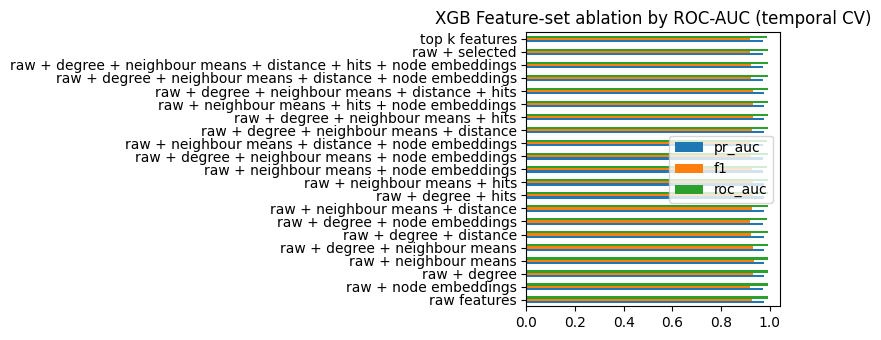

In [ ]:
# Select the feature set with the best temporal-CV ROC-AUC
BEST_SET = feature_selection["roc_auc"].idxmax()
best_cols = list(sets[BEST_SET])

print("Selected feature set:", BEST_SET, f"({len(best_cols)} features)")

# Plot the comparison
feature_selection[["pr_auc", "f1", "roc_auc"]].plot(kind="barh", figsize=(8, 3.5), title="XGB Feature-set ablation by ROC-AUC (temporal CV)")
plt.tight_layout()
plt.show()

### XGBoost Hyperparameter Tuning

In [ ]:
# Optuna hyper-parameter search for XGBoost (development period only, ROC-AUC objective)
# One trial: sample parameters, return the temporal-CV ROC-AUC
def xgb_objective(trial):
    trial_params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        n_estimators=trial.suggest_int("n_estimators", 200, 700),
        subsample=trial.suggest_float("subsample", 0.6, 1.0, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 0.8, log=True),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        reg_lambda=trial.suggest_int("reg_lambda", 1, 10),
        gamma=trial.suggest_int("gamma", 0, 5)
    )
    # Tune on the development period only and keep the complete parameter set (BASE_PARAMS + tuned) so the final model is the one that was tuned
    params = {**BASE_PARAMS, **trial_params}
    return cv_eval(labelled_graph_dev, best_cols, STRATEGY, params)["roc_auc"]

print("Tuning XGBoost Hyperparameters...")
# TPE sampler with a fixed seed
optuna_study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEED, n_startup_trials=15)
)

# Run the search
optuna_study.optimize(xgb_objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=False)

# Merge with BASE_PARAMS
best_params = {**BASE_PARAMS, **optuna_study.best_params}
print(f"Best temporal CV ROC-AUC Found: {optuna_study.best_value:.4f}")
print("Best Parameters:", best_params)

Tuning XGBoost Hyperparameters...
Best temporal CV ROC-AUC Found: 0.9942
Best Parameters: {'n_estimators': 275, 'learning_rate': 0.053513334131380506, 'max_depth': 10, 'subsample': 0.9865139845906269, 'colsample_bytree': 0.47626232071534386, 'min_child_weight': 4, 'tree_method': 'hist', 'eval_metric': 'auc', 'random_state': 42, 'n_jobs': 8, 'reg_lambda': 1, 'gamma': 2}


# 8. LightGBM Model

Building blocks, mirroring the XGBoost helpers (deterministic settings, imbalance strategies, temporal CV, permutation ranking)

In [ ]:
# LightGBM baseline parameters using deterministic + force_col_wise + fixed seeds to improve run-to-run reproducibility
LGB_BASE_PARAMS = dict(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    min_child_samples=20,
    reg_lambda=1.0,
    objective="binary",
    random_state=SEED,
    bagging_seed=SEED,
    feature_fraction_seed=SEED,
    data_random_seed=SEED,
    deterministic=True,
    force_col_wise=True,
    verbosity=-1,
    n_jobs=N_JOBS
)

# Apply the imbalance strategy to the training data only, then fit LightGBM
def fit_lgb_strategy(name, Xtr, ytr, params=LGB_BASE_PARAMS):
    p = dict(params)
    Xtr = np.asarray(Xtr, dtype=float)
    ytr = np.asarray(ytr, dtype=int)

    if name == "class_weight":
        p["scale_pos_weight"] = (ytr == 0).sum() / max((ytr == 1).sum(), 1)
    elif name == "undersample":
        rng = np.random.RandomState(SEED)
        pos, neg = np.where(ytr == 1)[0], np.where(ytr == 0)[0]
        keep = np.concatenate([
            pos,
            rng.choice(neg, min(len(neg), 4 * len(pos)), replace=False)
        ])
        Xtr, ytr = Xtr[keep], ytr[keep]
    elif name in ("smote", "smote_tomek"):
        Xtr = np.nan_to_num(Xtr, nan=0.0, posinf=0.0, neginf=0.0)
        if name == "smote":
            Xtr, ytr = SMOTE(sampling_strategy="auto", random_state=SEED).fit_resample(Xtr, ytr)
        else:
            Xtr, ytr = SMOTETomek(sampling_strategy="auto", random_state=SEED).fit_resample(Xtr, ytr)

    model = lgb.LGBMClassifier(**p)
    model.fit(Xtr, ytr)
    return model

# Average metrics over the expanding-window temporal folds
def lgb_cv_eval(df, cols, strategy, params=LGB_BASE_PARAMS):
    rows = []
    for tr_mask, va_mask in temporal_folds(df):
        ytr = df.loc[tr_mask, "y"].to_numpy(dtype=int)
        yva = df.loc[va_mask, "y"].to_numpy(dtype=int)
        if ytr.sum() == 0 or len(np.unique(ytr)) < 2 or yva.sum() == 0:
            continue
        model = fit_lgb_strategy(
            strategy, df.loc[tr_mask, cols].to_numpy(dtype=float), ytr, params
        )
        p = model.predict_proba(df.loc[va_mask, cols].to_numpy(dtype=float))[:, 1]
        r = metrics(yva, p, 0.5)
        r["f1_oracle"] = f1_score(
            yva, (p >= best_threshold(yva, p)).astype(int), zero_division=0
        )
        rows.append(r)
    return pd.DataFrame(rows).mean()

# Permutation-importance ranking on an inner temporal split
def lgb_rank_features(train_df, cols, strategy, params=LGB_BASE_PARAMS, n_repeats=5):
    fit_mask, imp_mask = inner_temporal_split(train_df)
    if fit_mask is None:
        return None

    fit_df = train_df.iloc[np.flatnonzero(fit_mask)]
    imp_df = train_df.iloc[np.flatnonzero(imp_mask)]
    y_fit = fit_df["y"].to_numpy(dtype=int)
    y_imp = imp_df["y"].to_numpy(dtype=int)
    if len(np.unique(y_fit)) < 2 or y_imp.sum() == 0:
        return None

    model = fit_lgb_strategy(
        strategy, fit_df[cols].to_numpy(dtype=float), y_fit, params
    )
    result = permutation_importance(
        estimator=model,
        X=imp_df[cols].to_numpy(dtype=float),
        y=y_imp,
        scoring="roc_auc",
        n_repeats=n_repeats,
        random_state=SEED,
        n_jobs=N_JOBS
    )
    return (
        pd.DataFrame({
            "feature": cols,
            "importance_mean": result.importances_mean,
            "importance_std": result.importances_std
        })
        .sort_values("importance_mean", ascending=False)
        .reset_index(drop=True)
    )

# Run the ranking inside every outer fold
def lgbm_cv_eval_perm(df, cols, strategy, params=LGB_BASE_PARAMS, n_repeats=5):
    importance_rows = []

    for fold_no, (tr, va) in enumerate(
        temporal_folds(df), start=1
    ):
        train_df = df.iloc[np.flatnonzero(tr)]
        val_df = df.iloc[np.flatnonzero(va)]

        ytr = train_df["y"].to_numpy(dtype=int)
        yva = val_df["y"].to_numpy(dtype=int)

        # Skip folds that cannot support binary classification
        if ytr.sum() == 0 or len(np.unique(ytr)) < 2:
            continue

        if yva.sum() == 0:
            continue

        # Rank features using the inner temporal split
        importance_df = lgb_rank_features(
            train_df=train_df,
            cols=cols,
            strategy=strategy,
            params=params,
            n_repeats=n_repeats
        )

        if importance_df is None:
            continue

        importance_df["fold"] = fold_no
        importance_rows.append(importance_df)

    importance_all = pd.concat(
        importance_rows, ignore_index=True
    ) if importance_rows else pd.DataFrame()

    return importance_all

# Evaluate the top-k features for several k in every fold
def lgb_cv_eval_topk(df, cols, strategy, top_k_values=TOP_K_VALUES,
                     params=LGB_BASE_PARAMS, n_repeats=5):
    rows, importance_rows = [], []
    for fold_no, (tr_mask, va_mask) in enumerate(temporal_folds(df), start=1):
        train_df = df.iloc[np.flatnonzero(tr_mask)]
        val_df = df.iloc[np.flatnonzero(va_mask)]
        ytr = train_df["y"].to_numpy(dtype=int)
        yva = val_df["y"].to_numpy(dtype=int)
        if ytr.sum() == 0 or len(np.unique(ytr)) < 2 or yva.sum() == 0:
            continue

        importance_df = lgb_rank_features(
            train_df, cols, strategy, params=params, n_repeats=n_repeats
        )
        if importance_df is None:
            continue
        importance_df["fold"] = fold_no
        importance_rows.append(importance_df)

        for k in top_k_values:
            if k > len(importance_df):
                continue
            selected_cols = importance_df["feature"].iloc[:k].tolist()
            model = fit_lgb_strategy(
                strategy, train_df[selected_cols].to_numpy(dtype=float), ytr, params
            )
            p = model.predict_proba(val_df[selected_cols].to_numpy(dtype=float))[:, 1]
            r = metrics(yva, p, 0.5)
            r["f1_oracle"] = f1_score(
                yva, (p >= best_threshold(yva, p)).astype(int), zero_division=0
            )
            r["fold"], r["n_features"] = fold_no, k
            rows.append(r)

    results_df = pd.DataFrame(rows)
    importance_all = (
        pd.concat(importance_rows, ignore_index=True)
        if importance_rows else pd.DataFrame()
    )
    return results_df, importance_all

In [ ]:
# Rank features for LightGBM on the development period (embeddings excluded), as for XGBoost
labelled_graph_with_deg_dev = labelled_graph_with_deg[labelled_graph_with_deg[TIME_COL] < t_hold0].reset_index(drop=True)

# Importance per fold
importance_all_perm_lgb = lgbm_cv_eval_perm(
    df=labelled_graph_with_deg_dev,
    cols=RAW + DEG_COLS + HITS_COLS + DIST_COLS,
    strategy="none",
    params=LGB_BASE_PARAMS,
    n_repeats=5
)

# Average across folds, best first
overall_importance_perm_lgb = (
    importance_all_perm_lgb
    .groupby("feature")
    .agg(
        mean_importance=("importance_mean", "mean"),
        std_across_folds=("importance_mean", "std"),
        mean_shuffle_std=("importance_std", "mean"),
        folds_ranked=("fold", "nunique")
    )
    .sort_values("mean_importance", ascending=False)
    .reset_index()
)

overall_importance_perm_lgb.head(TOP_K)

,feature,mean_importance,std_across_folds,mean_shuffle_std,folds_ranked
0,feat_2,0.003536,0.002192,0.000549,3
1,feat_59,0.000913,0.001231,0.000450,3
2,feat_53,0.000767,0.001149,0.000242,3
3,feat_132,0.000676,0.000420,0.000147,3
4,feat_58,0.000641,0.000504,0.000186,3
5,feat_125,0.000597,0.000895,0.000198,3
6,feat_163,0.000542,0.000758,0.000058,3
7,feat_161,0.000490,0.000601,0.000147,3
8,feat_16,0.000351,0.000488,0.000082,3
9,feat_9,0.000350,0.000472,0.000102,3


In [ ]:
# Neighbour means of LightGBM's own top-K features and the labelled frame used for LightGBM
# Add top K features to neighbour-aggregate
top_feats_rows_lgb = overall_importance_perm_lgb[:TOP_K]
top_feats_lgb = top_feats_rows_lgb["feature"]

# Features only, no labels
G_LGB = add_graph_features(allx_with_deg, top_feats_lgb)
NEIGH_COLS_LGB = [c for c in G_LGB.columns if c.startswith(("pred_mean_", "succ_mean_"))]

# Labelled training frame (with graph features)
labelled_graph_lgb = G_LGB[lab_mask].reset_index(drop=True)
labelled_graph_lgb_dev = labelled_graph_lgb[labelled_graph_lgb[TIME_COL] < t_hold0].reset_index(drop=True)
print("Development subset:", labelled_graph_lgb_dev.shape, "| hold-out rows excluded:", len(labelled_graph_lgb) - len(labelled_graph_lgb_dev))
print("View labelled_graph_lgb:")
print("Shape:", labelled_graph_lgb.shape)
labelled_graph_lgb.head(3)

Development subset: (25207, 283) | hold-out rows excluded: 6028
View labelled_graph_lgb:
Shape: (31235, 283)


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,pred_mean_feat_5,succ_mean_feat_5,pred_mean_feat_52,succ_mean_feat_52,pred_mean_feat_138,succ_mean_feat_138,pred_mean_feat_79,succ_mean_feat_79,pred_mean_feat_127,succ_mean_feat_127
0,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,0.032672,0.134776,-0.103652,1.874421,-0.255280,-0.077208,-0.208210,-0.263400,0.218233,-0.129496
1,232029206,1,-0.005027,0.578941,-0.091383,4.380281,-0.063725,4.667146,0.851305,-0.163645,...,-0.020324,0.055376,-0.127637,1.874421,-0.262448,-0.243274,-0.203817,-0.257636,-0.097895,-0.129496
2,232344069,1,-0.147852,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.137933,...,0.000000,-0.043875,0.000000,-0.377555,0.000000,-0.290451,0.000000,-0.183921,0.000000,-0.127462


In [ ]:
# Candidate feature pool for LightGBM feature selection: same pool as XGBoost (ALL_FEATURES)
ALL_FEATURES_LGB = RAW + DEG_COLS + NEIGH_COLS_LGB + DIST_COLS + HITS_COLS + EMB_COLS

TOP_K_VALUES = [50, 100, 150, 165, 200, 250]

### LightGBM: Imbalance Strategy

In [ ]:
# Compare class-imbalance strategies for LightGBM on the development period
lgb_imbalance = {
    strategy: lgb_cv_eval(labelled_graph_lgb_dev, RAW + EMB_COLS, strategy)
    for strategy in ["none", "class_weight", "undersample", "smote", "smote_tomek"]
}
lgb_imb_df = pd.DataFrame(lgb_imbalance).T.round(4)
lgb_imb_df

,precision,recall,f1,roc_auc,pr_auc,f1_oracle
none,0.9881,0.8522,0.9138,0.9924,0.9759,0.9386
class_weight,0.9718,0.8769,0.9211,0.9906,0.9727,0.9316
undersample,0.9562,0.8799,0.9153,0.9917,0.9733,0.9301
smote,0.9757,0.8715,0.9197,0.9924,0.9759,0.9353
smote_tomek,0.9757,0.8705,0.9191,0.9925,0.9764,0.9359


In [ ]:
# Pick the LightGBM imbalance strategy with the highest temporal-CV ROC-AUC
LGB_STRATEGY = lgb_imb_df["roc_auc"].idxmax()
print("Selected LightGBM imbalance strategy (highest temporal CV ROC-AUC):", LGB_STRATEGY)

Selected LightGBM imbalance strategy (highest temporal CV ROC-AUC): smote_tomek


### LightGBM: Feature Selection

In [ ]:
# LightGBM top-k feature-count search and summary
lgb_results_topk, lgb_importance_all = lgb_cv_eval_topk(
    df=labelled_graph_lgb_dev,
    cols=ALL_FEATURES_LGB,
    strategy=LGB_STRATEGY,
    top_k_values=TOP_K_VALUES,
    params=LGB_BASE_PARAMS,
    n_repeats=5
)

lgb_metric_cols = [
    c for c in ["precision", "recall", "f1", "pr_auc", "roc_auc", "f1_oracle"]
    if c in lgb_results_topk.columns
]
lgb_summary = (
    lgb_results_topk.groupby("n_features")[lgb_metric_cols].mean().round(4)
)
print(lgb_summary)

lgb_overall_importance = (
    lgb_importance_all.groupby("feature")
    .agg(
        mean_importance=("importance_mean", "mean"),
        std_across_folds=("importance_mean", "std"),
        mean_shuffle_std=("importance_std", "mean"),
        folds_ranked=("fold", "nunique")
    )
    .sort_values("mean_importance", ascending=False)
    .reset_index()
)
display(lgb_overall_importance.head(30))

            precision  recall      f1  pr_auc  roc_auc  f1_oracle
n_features                                                       
50             0.9637  0.8781  0.9181  0.9712   0.9909     0.9293
100            0.9640  0.8877  0.9237  0.9719   0.9908     0.9298
150            0.9717  0.8812  0.9233  0.9745   0.9913     0.9340
165            0.9749  0.8788  0.9234  0.9742   0.9916     0.9321
200            0.9748  0.8868  0.9279  0.9756   0.9919     0.9368
250            0.9759  0.8783  0.9237  0.9755   0.9921     0.9348


,feature,mean_importance,std_across_folds,mean_shuffle_std,folds_ranked
0,feat_5,0.004142,0.001544,0.000383,3
1,feat_2,0.003118,0.002830,0.000514,3
2,feat_163,0.000826,0.001121,0.000126,3
3,feat_58,0.000583,0.000700,0.000148,3
4,feat_61,0.000473,0.000790,0.000158,3
5,feat_59,0.000450,0.000379,0.000209,3
6,feat_161,0.000394,0.000354,0.000211,3
7,feat_8,0.000393,0.000136,0.000122,3
8,feat_9,0.000329,0.000474,0.000060,3
9,feat_53,0.000324,0.000234,0.000255,3


In [ ]:
# Candidate feature sets for LightGBM, compared by temporal-CV ROC-AUC
# Best feature count and the features that make it up
LGB_BEST_COUNT = int(lgb_summary["roc_auc"].idxmax())
lgb_best_count_features = lgb_overall_importance[:LGB_BEST_COUNT]
lgb_top_count_cols = lgb_best_count_features["feature"].tolist()
SELECT_LGB_COLS = [feature for feature in lgb_best_count_features["feature"] if feature not in RAW]

# Candidate feature sets
lgb_sets = {
    "raw features": RAW,
    "raw + node embeddings": RAW + EMB_COLS,
    "raw + degree": RAW + DEG_COLS,
    "raw + neighbour means": RAW + NEIGH_COLS_LGB,
    "raw + degree + neighbour means": RAW + DEG_COLS + NEIGH_COLS_LGB,
    "raw + degree + distance": RAW + DEG_COLS + DIST_COLS,
    "raw + degree + node embeddings": RAW + DEG_COLS + EMB_COLS,
    "raw + neighbour means + distance": RAW + DIST_COLS + NEIGH_COLS_LGB,
    "raw + degree + hits": RAW + DEG_COLS + HITS_COLS,
    "raw + neighbour means + hits": RAW + NEIGH_COLS_LGB + HITS_COLS,
    "raw + neighbour means + node embeddings": RAW + NEIGH_COLS_LGB + EMB_COLS,
    "raw + neighbour means + hits + node embeddings": RAW + NEIGH_COLS_LGB + HITS_COLS + EMB_COLS,
    "raw + degree + neighbour means + node embeddings": RAW + DEG_COLS + NEIGH_COLS_LGB + EMB_COLS,
    "raw + neighbour means + distance + node embeddings": RAW + NEIGH_COLS_LGB + DIST_COLS + EMB_COLS,
    "raw + degree + neighbour means + distance": RAW + DEG_COLS + DIST_COLS + NEIGH_COLS_LGB,
    "raw + degree + neighbour means + hits": RAW + DEG_COLS + NEIGH_COLS_LGB + HITS_COLS,
    "raw + degree + neighbour means + distance + hits": RAW + DEG_COLS + DIST_COLS + NEIGH_COLS_LGB + HITS_COLS,
    "raw + degree + neighbour means + distance + node embeddings": RAW + DEG_COLS + NEIGH_COLS_LGB + DIST_COLS + EMB_COLS,
    "raw + degree + neighbour means + distance + hits + node embeddings": RAW + DEG_COLS + DIST_COLS + NEIGH_COLS_LGB + HITS_COLS + EMB_COLS,
    "raw + selected": RAW + SELECT_LGB_COLS,
    "top k features": lgb_top_count_cols
}

# Evaluate every set with temporal CV
lgb_feature_selection = pd.DataFrame({
    name: lgb_cv_eval(labelled_graph_lgb_dev, cols, LGB_STRATEGY)
    for name, cols in lgb_sets.items()
}).T.round(4)
display(lgb_feature_selection)

,precision,recall,f1,roc_auc,pr_auc,f1_oracle
raw features,0.9736,0.8868,0.9271,0.9930,0.9772,0.9427
raw + node embeddings,0.9757,0.8705,0.9191,0.9925,0.9764,0.9359
raw + degree,0.9739,0.8946,0.9318,0.9930,0.9776,0.9446
raw + neighbour means,0.9744,0.8937,0.9315,0.9935,0.9791,0.9440
raw + degree + neighbour means,0.9757,0.8989,0.9351,0.9931,0.9789,0.9433
raw + degree + distance,0.9712,0.8782,0.9213,0.9927,0.9764,0.9408
raw + degree + node embeddings,0.9806,0.8688,0.9201,0.9924,0.9754,0.9341
raw + neighbour means + distance,0.9761,0.8863,0.9282,0.9934,0.9789,0.9423
raw + degree + hits,0.9737,0.8906,0.9295,0.9928,0.9772,0.9423
raw + neighbour means + hits,0.9764,0.8946,0.9331,0.9935,0.9792,0.9440


LightGBM selected feature set: raw + neighbour means (205 features)


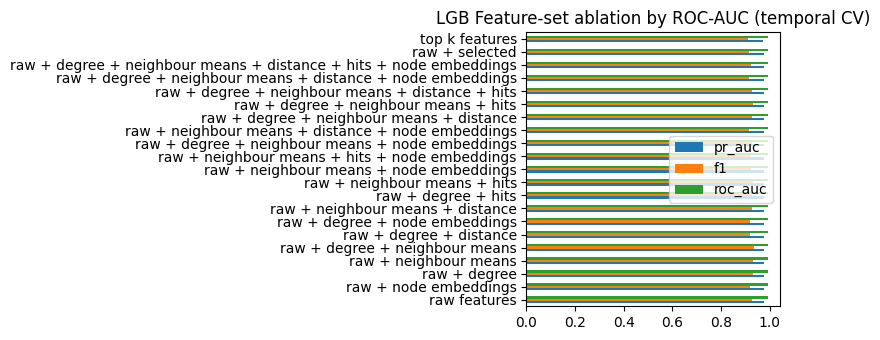

In [ ]:
# Select the LightGBM feature set with the best temporal-CV ROC-AUC
LGB_BEST_SET = lgb_feature_selection["roc_auc"].idxmax()
lgb_best_cols = list(lgb_sets[LGB_BEST_SET])
print("LightGBM selected feature set:", LGB_BEST_SET, f"({len(lgb_best_cols)} features)")

lgb_feature_selection[["pr_auc", "f1", "roc_auc"]].plot(kind="barh", figsize=(8, 3.5), title="LGB Feature-set ablation by ROC-AUC (temporal CV)")
plt.tight_layout()
plt.show()

### LightGBM: Hyperparameter Tuning

In [ ]:
# Optuna hyperparameter search for LightGBM (development period only, ROC-AUC objective)
# One trial: sample parameters, return the temporal-CV ROC-AUC
def lgb_objective(trial):
    trial_params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        n_estimators=trial.suggest_int("n_estimators", 200, 700),
        num_leaves=trial.suggest_int("num_leaves", 15, 63),
        max_depth=trial.suggest_int("max_depth", 3, 12),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 0.9),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 60),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True)
    )
    params = {**LGB_BASE_PARAMS, **trial_params}
    return lgb_cv_eval(labelled_graph_lgb_dev, lgb_best_cols, LGB_STRATEGY, params)["roc_auc"]

# TPE sampler with a fixed seed
lgb_optuna_study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEED, n_startup_trials=15)
)
lgb_optuna_study.optimize(
    lgb_objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=False
)
best_lgb_params = {**LGB_BASE_PARAMS, **lgb_optuna_study.best_params}
print(f"Best LightGBM temporal CV ROC-AUC: {lgb_optuna_study.best_value:.4f}")
print("Best LightGBM parameters:", best_lgb_params)

Best LightGBM temporal CV ROC-AUC: 0.9942
Best LightGBM parameters: {'n_estimators': 607, 'learning_rate': 0.016384278610333564, 'max_depth': 11, 'num_leaves': 28, 'subsample': 0.9166432955323746, 'subsample_freq': 1, 'colsample_bytree': 0.4289361925849209, 'min_child_samples': 39, 'reg_lambda': 0.0013649998323655014, 'objective': 'binary', 'random_state': 42, 'bagging_seed': 42, 'feature_fraction_seed': 42, 'data_random_seed': 42, 'deterministic': True, 'force_col_wise': True, 'verbosity': -1, 'n_jobs': 8}


# 9. Final Evaluation & Submission Generation

In [ ]:
# Hold-out evaluation for XGBoost: fit on the fit period, choose a threshold on validation, report on the hold-out
# Same 60 / 20 / 20 time split as in earlier ssection
steps = np.sort(labelled_graph[TIME_COL].unique())
n = len(steps)

# Split the labelled training dataset into train, validation, and test by time step
# First 60% into train, next 20% into validation and last 20% into test
t_val0, t_test0 = steps[int(n * 0.6)], steps[int(n * 0.8)]
tr   = labelled_graph[labelled_graph[TIME_COL] <  t_val0]
va   = labelled_graph[(labelled_graph[TIME_COL] >= t_val0) & (labelled_graph[TIME_COL] < t_test0)]
te = labelled_graph[labelled_graph[TIME_COL] >= t_test0]
print(f"Train: {len(tr)}, Illicit: {int(tr.y.sum())}")
print(f"Validation {len(va)}, Illicit {int(va.y.sum())}")
print(f"Hold out (Test) {len(te)}, Illicit {int(te.y.sum())}")

# Fit on the fit period: the threshold comes from validation, the metrics from the hold-out
def fit_eval(cols, params, strategy="none"):
    m = fit_strategy(strategy, tr[cols].values, tr.y.astype(int).values, params)
    thr = best_threshold(va.y.astype(int).values, m.predict_proba(va[cols].values)[:, 1])
    p = m.predict_proba(te[cols].values)[:, 1]
    r = metrics(te.y.astype(int).values, p, thr)
    r["threshold"] = thr
    return m, r, p

# Class ratio of the training split only (not the whole labelled set)
spw_tr = (tr.y == 0).sum() / (tr.y == 1).sum()
# Compare raw baseline, selected set, selected set with tuned parameters
base_p = {**BASE_PARAMS, "scale_pos_weight": spw_tr}
comparison = {
    "XGB raw (baseline)": fit_eval(RAW, base_p)[1],
    f"XGB {BEST_SET}": fit_eval(best_cols, base_p)[1],
    f"XGB {BEST_SET} (tuned)": fit_eval(best_cols, best_params, STRATEGY)[1],
}
xgboost_results_df = pd.DataFrame(comparison).T.round(4)

Train: 19530, Illicit: 1871
Validation 5677, Illicit 671
Hold out (Test) 6028, Illicit 1102


Confusion matrix for XGBoost (rows = true, cols = predicted):
 [[4901   25]
 [ 400  702]]


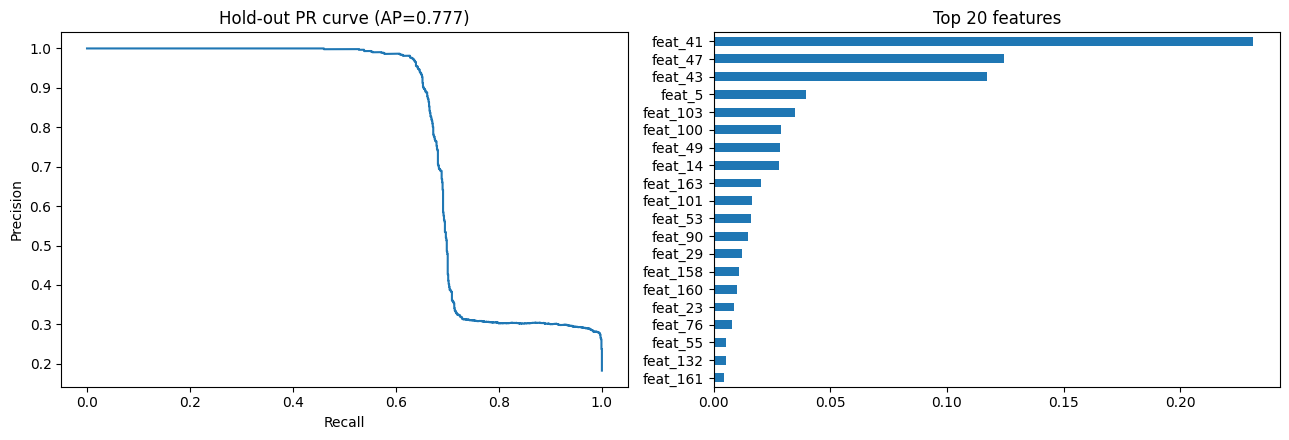

In [89]:
m, r, p = fit_eval(best_cols, best_params, STRATEGY)
thr = r["threshold"]
yh = te.y.astype(int).values
print("Confusion matrix for XGBoost (rows = true, cols = predicted):\n", confusion_matrix(yh, (p >= thr).astype(int)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
pr, rc, _ = precision_recall_curve(yh, p)
ax[0].plot(rc, pr)
ax[0].set(xlabel="Recall", ylabel="Precision", title=f"Hold-out PR curve (AP={r['pr_auc']:.3f})")
pd.Series(m.feature_importances_, index=best_cols).nlargest(20)[::-1].plot(kind="barh", ax=ax[1], title="Top 20 features")
plt.tight_layout()
plt.show()

In [ ]:
# Same hold-out evaluation for LightGBM
steps = np.sort(labelled_graph_lgb[TIME_COL].unique())
n = len(steps)

# Split the labelled training dataset into train, validation, and test by time step
# First 60% into train, next 20% into validation and last 20% into test
t_val0, t_test0 = steps[int(n * 0.6)], steps[int(n * 0.8)]
tr   = labelled_graph_lgb[labelled_graph_lgb[TIME_COL] <  t_val0]
va   = labelled_graph_lgb[(labelled_graph_lgb[TIME_COL] >= t_val0) & (labelled_graph_lgb[TIME_COL] < t_test0)]
te = labelled_graph_lgb[labelled_graph_lgb[TIME_COL] >= t_test0]
print(f"Train: {len(tr)}, Illicit: {int(tr.y.sum())}")
print(f"Validation {len(va)}, Illicit {int(va.y.sum())}")
print(f"Hold out (Test) {len(te)}, Illicit {int(te.y.sum())}")

# Fit on the fit period, threshold from validation, metrics on the hold-out
def fit_eval_lgb(cols, params, strategy="none"):
    m = fit_lgb_strategy(strategy, tr[cols].values, tr.y.astype(int).values, params)
    thr = best_threshold(va.y.astype(int).values, m.predict_proba(va[cols].values)[:, 1])
    p = m.predict_proba(te[cols].values)[:, 1]
    r = metrics(te.y.astype(int).values, p, thr)
    r["threshold"] = thr
    return m, r, p

# Class ratio of the training split only
spw_tr = (tr.y == 0).sum() / (tr.y == 1).sum()
# Compare raw baseline, selected set, selected set with tuned parameters
base_p = {**LGB_BASE_PARAMS}
comparison = {
    "LGB raw (baseline)": fit_eval_lgb(RAW, base_p)[1],
    f"LGB {LGB_BEST_SET}": fit_eval_lgb(lgb_best_cols, base_p)[1],
    f"LGB {LGB_BEST_SET} (tuned)": fit_eval_lgb(lgb_best_cols, best_lgb_params, LGB_STRATEGY)[1],
}
lgb_results_df = pd.DataFrame(comparison).T.round(4)

Train: 19530, Illicit: 1871
Validation 5677, Illicit 671
Hold out (Test) 6028, Illicit 1102


Confusion matrix for LGB (rows = true, cols = predicted):
 [[4891   35]
 [ 396  706]]


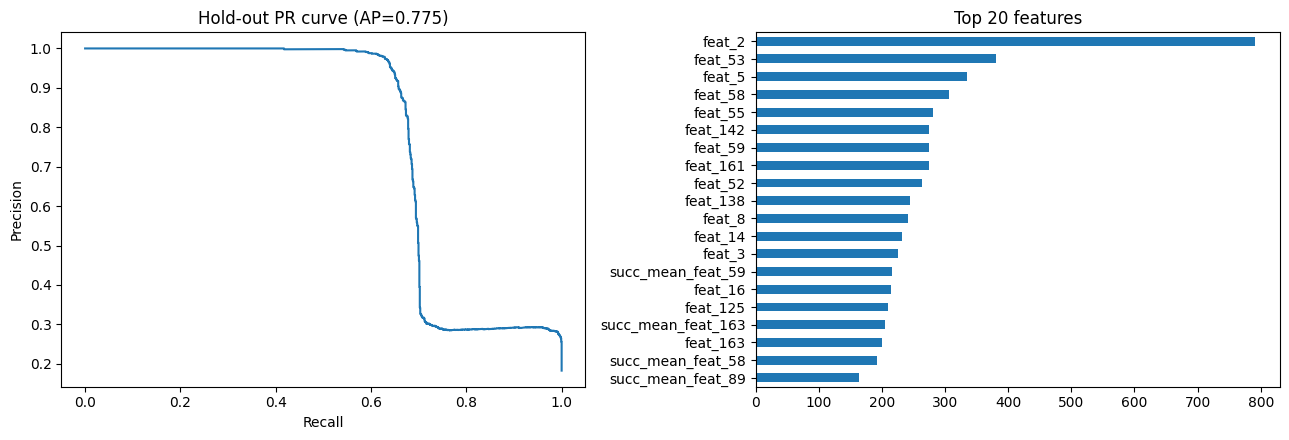

In [91]:
m, r, p = fit_eval_lgb(lgb_best_cols, best_lgb_params, LGB_STRATEGY)
thr = r["threshold"]
yh = te.y.astype(int).values
print("Confusion matrix for LGB (rows = true, cols = predicted):\n", confusion_matrix(yh, (p >= thr).astype(int)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
pr, rc, _ = precision_recall_curve(yh, p)
ax[0].plot(rc, pr)
ax[0].set(xlabel="Recall", ylabel="Precision", title=f"Hold-out PR curve (AP={r['pr_auc']:.3f})")
pd.Series(m.feature_importances_, index=lgb_best_cols).nlargest(20)[::-1].plot(kind="barh", ax=ax[1], title="Top 20 features")
plt.tight_layout()
plt.show()

In [ ]:
# Combine both result tables for easier comparison
compare_results = pd.concat([xgboost_results_df, lgb_results_df])

compare_results

,precision,recall,f1,roc_auc,pr_auc,threshold
XGB raw (baseline),0.9848,0.5871,0.7356,0.8394,0.7609,0.9052
XGB raw + neighbour means + hits,0.9591,0.6388,0.7669,0.7662,0.7426,0.6663
XGB raw + neighbour means + hits (tuned),0.9656,0.6370,0.7676,0.8657,0.7774,0.7103
LGB raw (baseline),0.9859,0.5726,0.7245,0.8095,0.7527,0.7989
LGB raw + neighbour means,0.9540,0.6397,0.7659,0.7740,0.7466,0.3596
LGB raw + neighbour means (tuned),0.9528,0.6407,0.7661,0.8580,0.7746,0.5692


In [ ]:
# Pick the model with the highest hold-out ROC-AUC
BEST_MODEL = compare_results["roc_auc"].idxmax()
print(BEST_MODEL)

XGB raw + neighbour means + hits (tuned)


In [ ]:
# Refit the chosen model on all labelled rows and write the submission (index merged on txId, test.csv order kept)
if ("XGB" in BEST_MODEL):
    # XGBoost branch: refit on all labelled rows and score the test rows
    final = fit_strategy(STRATEGY, labelled_graph[best_cols].values, labelled_graph.y.astype(int).values, best_params)
    final_test = G[(allx.split == "test").values]
    p_final = final.predict_proba(final_test[best_cols].values)[:, 1]
    # Attach 'index' by merging on txId (keeps test.csv order, and fails loudly if anything is missing)
    SUB_INDEX_COL = "index"
    assert SUB_INDEX_COL in test.columns, f"test.csv has no '{SUB_INDEX_COL}' column: {list(test.columns[:6])}"
    preds = pd.DataFrame({ID_COL: final_test[ID_COL].values, "target": p_final})
    submission = test[[SUB_INDEX_COL, ID_COL]].merge(preds, on=ID_COL, how="left")
    assert len(submission) == len(test) and submission["target"].notna().all() and submission[SUB_INDEX_COL].is_unique
    submission = submission[[SUB_INDEX_COL, "target"]].rename(columns={SUB_INDEX_COL: "index"})
    submission["index"] = submission["index"].astype(int)

    submission.to_csv(f"submission_version_{VER_NO}.csv", index=False)

    print(submission.shape)
    submission.head()
else:
    # LightGBM branch: refit on all labelled rows and score the test rows
    final = fit_lgb_strategy(LGB_STRATEGY, labelled_graph_lgb[lgb_best_cols].values, labelled_graph_lgb.y.astype(int).values, best_lgb_params)
    final_test = G_LGB[(allx.split == "test").values]
    p_final = final.predict_proba(final_test[lgb_best_cols].values)[:, 1]

    # Attach 'index' by merging on txId (keeps test.csv order, and fails loudly if anything is missing)
    SUB_INDEX_COL = "index"
    assert SUB_INDEX_COL in test.columns, f"test.csv has no '{SUB_INDEX_COL}' column: {list(test.columns[:6])}"
    preds = pd.DataFrame({ID_COL: final_test[ID_COL].values, "target": p_final})
    submission = test[[SUB_INDEX_COL, ID_COL]].merge(preds, on=ID_COL, how="left")
    assert len(submission) == len(test) and submission["target"].notna().all() and submission[SUB_INDEX_COL].is_unique
    submission = submission[[SUB_INDEX_COL, "target"]].rename(columns={SUB_INDEX_COL: "index"})
    submission["index"] = submission["index"].astype(int)

    submission.to_csv(f"submission_version_{VER_NO}.csv", index=False)

    print(submission.shape)
    submission.head()

(15329, 2)
